# Biot kernel closure for the 443-member ensemble average

In [1]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****
# Method reference: Jalalian et al. (2025), Sec. 2.1, https://arxiv.org/abs/2503.01036v2.
# We use the two-step solution/equation-kernel idea to fit a ten-term closure for a fixed Biot operator.
# The nodal closure, choice of basis and gradient penalty are specific to this study.
# Poroelasticity: M. A. Biot (1941), https://doi.org/10.1063/1.1712886.

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Math, display
from matplotlib.colors import ListedColormap, SymLogNorm
from matplotlib.ticker import FuncFormatter, NullLocator
from scipy import sparse

root = Path.cwd().resolve()
dataset = root / "data/443EA_CLEAN_ICSTRAIN0.1_P_U1_U2.npz"
outputs = root / "outputs/kernel"
outputs.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(root / "src"))
from kernel import data
from kernel.fem import LinearFactor
from kernel.library import HEADS, OLD_NAMES, assemble, build_library, embed_biot, rates
from kernel.metrics import score
from kernel.operators import build_system, context
from kernel.pipeline import prior_rowweights
from kernel.regression import raw_batch, solve_centered_delta
from kernel.solution import fit_internal_solution
from material_sim.base.fbm500_biot_core import material_from_mean_k

data.DATA = dataset
last_training_frame = 38
solution_penalty = 1e-8
ridge = 0.1
gradient_amplitude = 0.1
batch_size = 512
display_head = {"P": "P", "U1": "Ux", "U2": "Uy"}

In [2]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

meta = data.metadata()
free = data.free_ids(meta)
xy = meta["node_xy_m"]
node_count = len(xy)
training_fields = data.read_prefix(last_training_frame)
training_times = meta["times_s"][:last_training_frame + 1]
observations = np.stack([training_fields[h][0] for h in HEADS], axis=1)
state_scales = np.array([np.std(training_fields[h][0, 1:, free[h]]) for h in HEADS])
with np.load(dataset, allow_pickle=False) as source:
    permeability = float(source["k_ref_md"]) * np.exp(source["mean_logk_elem"])
material = material_from_mean_k(permeability)
material_fields = {"k (mD)": permeability, "Porosity": material["phi"], "E (Pa)": material["E"],
                   "λ (Pa)": material["lam"], "G (Pa)": material["G"], "Biot α": material["alpha_mech"],
                   "S (1/Pa)": material["S"], "Mobility (m²/(Pa·s))": material["mobility"]}
display(pd.DataFrame({name: [field.min(), field.mean(), field.max()]
                      for name, field in material_fields.items()}, index=["Minimum", "Mean", "Maximum"]).T)

,Minimum,Mean,Maximum
k (mD),7.257889e-01,1.006200e+00,1.332610e+00
Porosity,1.823668e-01,2.000843e-01,2.169659e-01
E (Pa),2.264273e+10,2.399326e+10,2.541066e+10
λ (Pa),9.057091e+09,9.597303e+09,1.016426e+10
G (Pa),9.057091e+09,9.597303e+09,1.016426e+10
Biot α,5.294323e-01,5.556804e-01,5.806902e-01
S (1/Pa),9.253471e-11,1.008251e-10,1.087243e-10
Mobility (m²/(Pa·s)),7.162980e-13,9.930419e-13,1.315184e-12


In [3]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

baseline = build_system(data.time_slice(meta, last_training_frame), state_scales)
inputs = {name: value for name, value in meta.items() if not name.startswith("mean_")}
row_scales = baseline.row_scales
training = context(inputs, training_times, state_scales, row_scales)
libraries = build_library(training["engine"], state_scales, row_scales)
stabilization = baseline.engine.assemble(baseline.coefficients).tau
biot = embed_biot(libraries, baseline.coefficients, stabilization)
A_biot, M_biot, offset_biot = assemble(libraries, biot)
row_weights = prior_rowweights(A_biot, M_biot, training_times, training["fixed"], node_count)
print("Training frames:", len(training_times), "| Nodes:", node_count)
print("Closure library:", ", ".join(OLD_NAMES))

Training frames: 39 | Nodes: 10201
Closure library: 1, U1_I, U2_I, P_I, U1_Dx, U1_Dy, U2_Dx, U2_Dy, P_Dx, P_Dy


In [4]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

fixed_mask = np.ones((3, node_count), dtype=bool)
for j, h in enumerate(HEADS):
    fixed_mask[j, free[h]] = False
known_boundary = (training["known"] * np.repeat(state_scales, node_count)).reshape(3, node_count)
fitted_fields, solution = fit_internal_solution(
    observations, training_times, np.arange(len(training_times)), meta["x_m"], meta["y_m"],
    fixed_mask, known_boundary, state_scales, eta=solution_penalty, space_reg=1.0, time_reg=1.0,
)
state = np.concatenate([fitted_fields[h] / state_scales[j] for j, h in enumerate(HEADS)], axis=1)
derivatives_t = rates(state, training_times)
cg_result = solution["linear_solve"]
print("Solution objective:", solution["objective_value"])
print("PCG iterations:", cg_result["iterations"], "| Relative residual:", cg_result["relative_residual"])
display(pd.Series({display_head[h]: solution["observed_value_fit_unconstrained"][h]["R2"]
                   for h in HEADS}, name="Training field R²"))

Solution objective: 0.0342367757503622
PCG iterations: 2 | Relative residual: 1.4077598526556455e-16


Ux    1.0
Uy    1.0
P     1.0
Name: Training field R², dtype: float64

In [5]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

feature_scales = []
for hidx, library in enumerate(libraries):
    weights = row_weights[:, hidx * node_count:(hidx + 1) * node_count]
    scale = np.ones((node_count, len(library)))
    global_square = np.zeros(len(library))
    for start in range(0, node_count, batch_size):
        ids = np.arange(start, min(start + batch_size, node_count))
        raw = raw_batch(library, state, derivatives_t, ids)
        square = np.mean((raw * weights[:, ids, None])**2, axis=0)
        scale[ids] = np.sqrt(square)
        global_square += square.sum(axis=0) / node_count
    scale = np.maximum(scale, np.maximum(np.sqrt(global_square) * 1e-4, 1e-14)[None, :])
    amplitude = np.ones(len(library))
    amplitude[4:10] = gradient_amplitude
    feature_scales.append(scale / amplitude[None, :])

In [6]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

total_coefficients = []
fit_rows = []
for hidx, (h, library, prior, scale) in enumerate(zip(HEADS, libraries, biot, feature_scales)):
    weights = row_weights[:, hidx * node_count:(hidx + 1) * node_count]
    learned = np.array([term.family == "old_closure" for term in library])
    coefficients = prior.copy()
    residual_loss = penalty_loss = 0.0
    max_kkt_residual = 0.0
    for start in range(0, len(free[h]), batch_size):
        ids = free[h][start:start + batch_size]
        raw = raw_batch(library, state, derivatives_t, ids)
        prior_value = np.einsum("tnj,nj->tn", raw, prior[ids])
        target = (training["rhs"][:, hidx * node_count + ids] - prior_value) * weights[:, ids]
        X = (raw * weights[:, ids, None] / scale[None, ids, :])[:, :, learned]
        theta, optimality = solve_centered_delta(X, target, ridge)
        coefficients[np.ix_(ids, learned)] += theta / scale[np.ix_(ids, learned)]
        residual = np.einsum("tnj,nj->tn", X, theta) - target
        residual_loss += 0.5 * np.sum(residual**2) / len(training_times)
        penalty_loss += 0.5 * np.sum(theta**2 * ridge)
        max_kkt_residual = max(max_kkt_residual, optimality["KKT_normalized_max_error"])
    total_coefficients.append(coefficients)
    fit_rows.append((display_head[h], len(free[h]), int(learned.sum()), residual_loss / node_count,
                     penalty_loss / node_count, max_kkt_residual))
fit_table = pd.DataFrame(fit_rows, columns=["Equation", "Free nodes", "Learned terms",
                                           "Residual loss", "RKHS penalty", "Max KKT residual"])
display(fit_table)
print("Total ridge objective:", fit_table[["Residual loss", "RKHS penalty"]].sum().sum())

,Equation,Free nodes,Learned terms,Residual loss,RKHS penalty,Max KKT residual
0,Ux,10000,10,4.117725e-09,6.824852e-08,2.917690e-15
1,Uy,10100,10,8.188528e-09,1.680175e-07,3.217934e-15
2,P,10189,10,3.775375e-07,2.063003e-06,4.087532e-15


Total ridge objective: 2.689112518718269e-06


In [7]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

A_total, M_total, offset = assemble(libraries, total_coefficients)
model = outputs / "fixed_biot_control"
model.mkdir(exist_ok=True)
sparse.save_npz(model / "A_total.npz", A_total)
sparse.save_npz(model / "M_total.npz", M_total)
np.savez_compressed(model / "kernel.npz", state_scales=state_scales, row_scales=row_scales, offset=offset,
    **{f"weights_{h}": c * s for h, c, s in zip(HEADS, total_coefficients, feature_scales)},
    **{f"coefficients_{h}": c for h, c in zip(HEADS, total_coefficients)},
    **{f"feature_scales_{h}": s for h, s in zip(HEADS, feature_scales)},
    **{f"prior_coefficients_{h}": b for h, b in zip(HEADS, biot)},
    **{f"features_{h}": np.array([term.name for term in lib]) for h, lib in zip(HEADS, libraries)})
names = list(OLD_NAMES)
coeff = {h: c[:, :len(names)].copy() for h, c in zip(HEADS, total_coefficients)}
np.savez_compressed(outputs / "rediscovered_coefficients.npz", node_xy_m=xy, feature_order=names,
    state_scales_Ux_Uy_P=state_scales, **{display_head[h]: coeff[h] for h in HEADS},
    **{"free_" + display_head[h]: free[h] for h in HEADS})
features_tex = [r"1", r"\widetilde U_x", r"\widetilde U_y", r"\widetilde P",
                r"\frac{\partial\widetilde U_x}{\partial x}", r"\frac{\partial\widetilde U_x}{\partial y}",
                r"\frac{\partial\widetilde U_y}{\partial x}", r"\frac{\partial\widetilde U_y}{\partial y}",
                r"\frac{\partial\widetilde P}{\partial x}", r"\frac{\partial\widetilde P}{\partial y}"]
display(Math(r"x=\frac{X}{500\,\mathrm{m}},\quad y=\frac{Y}{500\,\mathrm{m}},\quad "
             r"\widetilde v_h=\frac{v_h}{\sigma_h},\quad h\in\{U_x,U_y,P\}"))
display(Math(r"\mathcal{B}^0_{h,i}=\big[A^0s+M^0\dot s+o^0\big]_{h,i}"))
display(Math(r"\Phi=\left(" + r",\;".join(features_tex) + r"\right)"))
for symbol in ("P", "U_x", "U_y"):
    display(Math(rf"\mathcal{{B}}^0_{{{symbol},i}}+\sum_{{j=0}}^{{9}} b_{{{symbol},ij}}\,\Phi_{{ij}}=f_{{{symbol},i}}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [8]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

features = raw_batch(libraries[0][:len(names)], state, derivatives_t, np.arange(node_count))
shares = {}
for hidx, h in enumerate(HEADS):
    weights = row_weights[:, hidx * node_count:(hidx + 1) * node_count]
    weighted_terms = features * weights[:, :, None] * coeff[h][None, :, :]
    norms = np.sqrt(np.sum(weighted_terms**2, axis=(0, 1)))
    shares[h] = 100 * norms / norms.sum()
table = pd.DataFrame({display_head[h]: shares[h] for h in ("P", "U1", "U2")}, index=names)
table.index.name = "Closure feature"
table.to_csv(outputs / "term_norm_shares_percent.csv")
display(table.round(3))

,P,Ux,Uy
Closure feature,,,
1,30.335,26.864,23.792
U1_I,26.097,26.039,24.308
U2_I,13.736,19.452,25.517
P_I,28.227,26.157,24.946
U1_Dx,0.267,0.266,0.252
U1_Dy,0.253,0.242,0.224
U2_Dx,0.242,0.242,0.229
U2_Dy,0.244,0.247,0.252
P_Dx,0.292,0.228,0.241


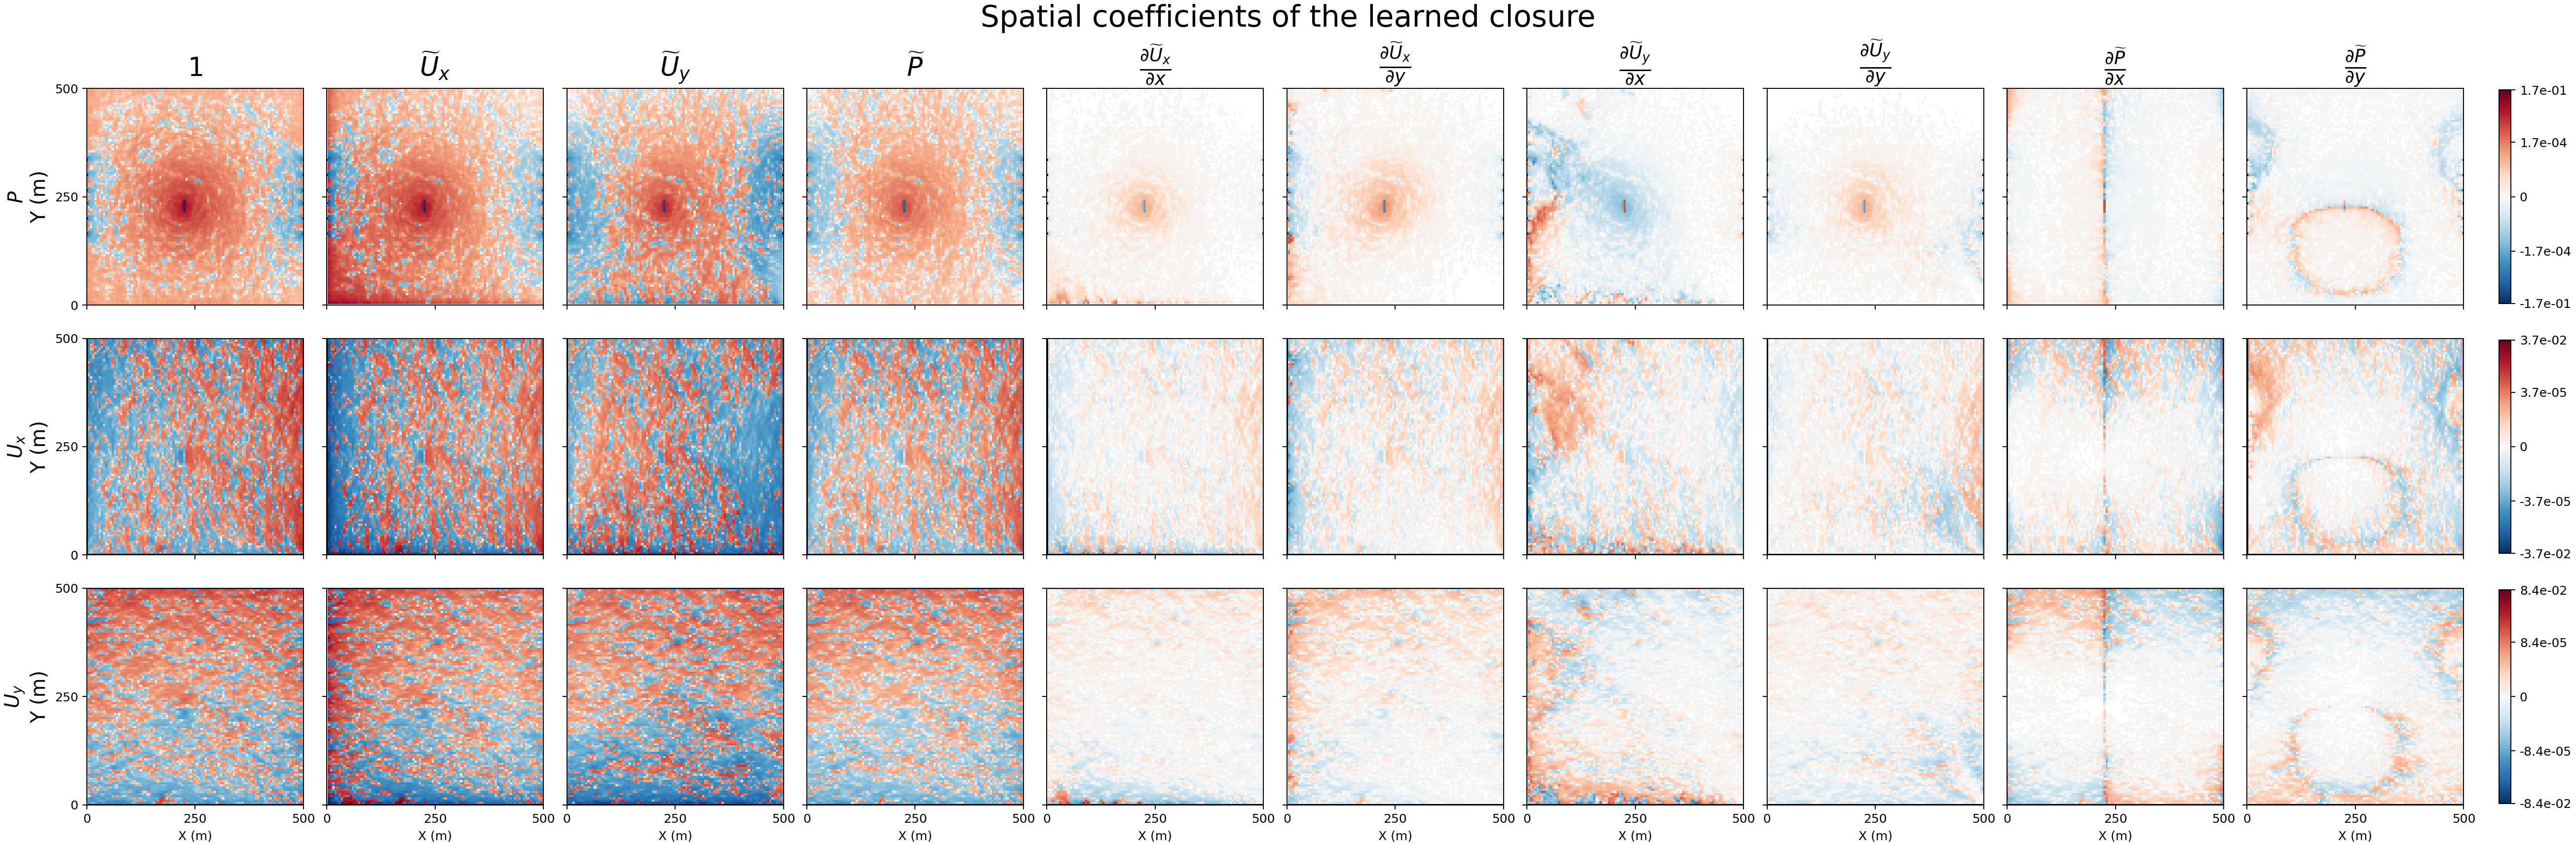

In [9]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

colors = plt.get_cmap("RdBu_r")(np.linspace(0, 1, 257))
colors[128] = [1, 1, 1, 1]
cmap = ListedColormap(colors)
cmap.set_bad("black")
fig, axes = plt.subplots(3, len(names), figsize=(29, 9.5), layout="constrained")
x, y = meta["x_m"], meta["y_m"]
for row, (h, symbol) in enumerate(zip(("P", "U1", "U2"), ("$P$", "$U_x$", "$U_y$"))):
    limit = np.max(np.abs(coeff[h][free[h]]))
    norm = SymLogNorm(linthresh=1e-5 * limit, vmin=-limit, vmax=limit, base=10)
    mask = np.ones(node_count, dtype=bool)
    mask[free[h]] = False
    for col, title in enumerate(features_tex):
        ax = axes[row, col]
        field = np.ma.array(coeff[h][:, col], mask=mask).reshape(len(y), len(x))
        image = ax.pcolormesh(x, y, field, shading="nearest", cmap=cmap, norm=norm, rasterized=True)
        ax.set(aspect="equal", xlim=(0, 500), ylim=(0, 500), xticks=[0, 250, 500], yticks=[0, 250, 500])
        if row == 0:
            ax.set_title("$" + title + "$", fontsize=21, pad=10)
        if row == 2:
            ax.set_xlabel("X (m)")
        if col == 0:
            ax.set_ylabel(symbol + "\nY (m)", fontsize=16)
        ax.tick_params(labelbottom=row == 2, labelleft=col == 0)
    ticks = [-limit, -limit * 1e-3, 0, limit * 1e-3, limit]
    cbar = fig.colorbar(image, ax=axes[row, :].tolist(), ticks=ticks, shrink=0.88, pad=0.01, aspect=18)
    cbar.formatter = FuncFormatter(lambda value, pos: "0" if value == 0 else f"{value:.1e}")
    cbar.update_ticks()
    cbar.ax.yaxis.set_minor_locator(NullLocator())
fig.suptitle("Spatial coefficients of the learned closure", fontsize=24)
plot_path = outputs / "closure_coefficients_g0p1_3x10_symlog_shared_rows.png"
fig.savefig(plot_path, dpi=180)
plt.close(fig)
display(Image(filename=str(plot_path), width=1500))

In [10]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

A_frozen = sparse.load_npz(model / "A_total.npz").tocsr()
M_frozen = sparse.load_npz(model / "M_total.npz").tocsr()
with np.load(model / "kernel.npz") as frozen:
    offset_frozen = frozen["offset"]
    scales_frozen = frozen["state_scales"]
    rows_frozen = frozen["row_scales"]
solver_times = inputs["solver_times_s"]
forward = context(inputs, solver_times, scales_frozen, rows_frozen)
free_rows, fixed_rows = forward["free"], forward["fixed"]
trajectory = np.empty((len(solver_times), 3 * node_count))
trajectory[0] = np.concatenate([training_fields[h][0, 0] / scales_frozen[j] for j, h in enumerate(HEADS)])
step_residuals = []
for step, dt in enumerate(np.diff(solver_times), start=1):
    matrix = (A_frozen + M_frozen / dt).tocsr()
    rhs = forward["rhs"][step] - offset_frozen + M_frozen @ trajectory[step - 1] / dt
    current = forward["known"].copy()
    reduced_rhs = rhs[free_rows] - matrix[free_rows][:, fixed_rows] @ current[fixed_rows]
    factor = LinearFactor(matrix[free_rows][:, free_rows], np.ones(len(free_rows)))
    solved, residual = factor.solve(reduced_rhs[:, None])
    current[free_rows] = solved[:, 0]
    if not np.isfinite(current).all() or np.max(np.abs(current)) > 1e12:
        raise FloatingPointError(f"Invalid normalized state at step {step}")
    trajectory[step] = current
    step_residuals.append(residual)
    if step == 1 or step % 10 == 0 or step == len(solver_times) - 1:
        print(f"Step {step:2d}/{len(solver_times) - 1}   day {solver_times[step] / 86400:8.3f}   residual {residual:.2e}")
physical = (trajectory * np.repeat(scales_frozen, node_count)[None, :]).reshape(len(solver_times), 3, node_count)
for j, h in enumerate(HEADS):
    physical[0, j] = training_fields[h][0, 0]
predicted = physical[inputs["output_solver_step_indices"]]
times = inputs["times_s"]
np.savez_compressed(model / "full_forward.npz", fields=predicted, times_s=times, field_order=HEADS)

Step  1/70   day    0.000   residual 4.53e-16


Step 10/70   day    0.041   residual 4.47e-15


Step 20/70   day   30.417   residual 7.03e-15


Step 30/70   day  152.083   residual 1.01e-14


Step 40/70   day  304.167   residual 1.11e-14


Step 50/70   day  441.042   residual 1.13e-14


Step 60/70   day  593.125   residual 1.14e-14


Step 70/70   day  730.000   residual 5.06e-15


In [11]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****

with np.load(dataset, allow_pickle=False) as source:
    truth = np.stack([source[h + "_EA"][0] for h in HEADS], axis=1)
splits = {"train":slice(1,39), "temporal_heldout":slice(39,49), "last":slice(48,49)}
results = []
for h in ("P","U1","U2"):
    hidx, label = HEADS.index(h), display_head[h]
    scale, unit = (1e-6,"MPa") if h == "P" else (1e3,"mm")
    for interval, frames in splits.items():
        y = truth[frames,hidx][:,free[h]] * scale
        p = predicted[frames,hidx][:,free[h]] * scale
        metrics = score(y,p)
        results.append((label,interval,len(free[h]),metrics["R2"],metrics["relative_L2"]*100,
                        metrics["absolute_L2"],unit))
summary = pd.DataFrame(results, columns=["Field","Split","Free nodes","R²","Relative L2 (%)",
                                          "Absolute L2","L2 unit"])
summary.to_csv(outputs / "frozen_forward_scores.csv", index=False)
display(summary.round(5))

,Field,Split,Free nodes,R²,Relative L2 (%),Absolute L2,L2 unit
0,P,train,10189,0.99407,2.16162,272.52975,MPa
1,P,temporal_heldout,10189,0.99194,2.26146,158.32964,MPa
2,P,last,10189,0.98947,2.57839,57.28013,MPa
3,Ux,train,10000,0.99871,2.27479,1738.31866,mm
4,Ux,temporal_heldout,10000,0.99552,4.24808,1796.69326,mm
5,Ux,last,10000,0.99479,4.58504,615.45131,mm
6,Uy,train,10100,0.99427,4.90978,2264.87874,mm
7,Uy,temporal_heldout,10100,0.98254,7.90229,2196.86787,mm
8,Uy,last,10100,0.97937,8.57290,759.28527,mm
